# Mission 02: A Governed Taxi Feed

A partner sends the city's taxi trips through Kafka once a day. The data platform team loads each day into an
Iceberg table that dashboards read. Last quarter, bad deliveries reached the dashboards three times. Build a
loader that **cannot publish bad data**: a schema contract at the producer, **write-audit-publish** on an Iceberg
branch, quality and volume checks, and lineage events for every run.

**Lessons used:** 05 (Iceberg REST catalog, branches), 06 (Avro, Schema Registry, data contracts),
07 (observability, OpenLineage, Marquez).

**Data:** NYC yellow taxi trips 2024-01-08 to 2024-01-17, a 10 % sample (every 10th trip).
Four incidents are built into the deliveries; your loader must find them without knowing them.

**Services:** `docker compose -f docker/compose.yml --profile streaming --profile lakehouse --profile lineage up -d
kafka schema-registry rustfs iceberg-rest postgres marquez`

In [1]:
import datetime as dt
import json
import struct
import subprocess
import sys
import time
import uuid
from pathlib import Path

import boto3
import matplotlib.pyplot as plt
import pandas as pd
import pyarrow as pa
import requests
from confluent_kafka import Consumer, Producer
from confluent_kafka.admin import AdminClient, NewTopic
from confluent_kafka.schema_registry import SchemaRegistryClient
from confluent_kafka.schema_registry.avro import AvroDeserializer, AvroSerializer
from confluent_kafka.serialization import MessageField, SerializationContext
from openlineage.client import OpenLineageClient
from openlineage.client.event_v2 import InputDataset, Job, OutputDataset, Run, RunEvent, RunState
from openlineage.client.facet_v2 import error_message_run, output_statistics_output_dataset
from openlineage.client.transport.http import HttpConfig, HttpTransport
from pyiceberg.catalog import load_catalog

sys.path.insert(0, str(Path.cwd().parent.parent / "tools"))
import datasets                                   # course helper: pinned datasets and Docker services

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
for profile, svc in [("streaming", "kafka"), ("streaming", "schema-registry"), ("lakehouse", "rustfs"),
                     ("lakehouse", "iceberg-rest"), ("lineage", "postgres")]:
    datasets.ensure_service(profile, svc, timeout=240)
# Marquez's default config expects database, user and password "marquez"
psql = ["docker", "compose", "-f", str(datasets.COMPOSE), "exec", "-T", "postgres", "psql", "-U", "course", "-d", "course", "-tAc"]
if subprocess.run(psql + ["SELECT 1 FROM pg_roles WHERE rolname = 'marquez'"], capture_output=True, text=True).stdout.strip() != "1":
    subprocess.run(psql + ["CREATE ROLE marquez LOGIN PASSWORD 'marquez'"], check=True, capture_output=True)
if subprocess.run(psql + ["SELECT 1 FROM pg_database WHERE datname = 'marquez'"], capture_output=True, text=True).stdout.strip() != "1":
    subprocess.run(psql + ["CREATE DATABASE marquez OWNER marquez"], check=True, capture_output=True)
# each Marquez event is one transaction; on Docker Desktop disks a synchronous commit (fsync) takes seconds
subprocess.run(psql + ["ALTER ROLE marquez SET synchronous_commit = off"], check=True, capture_output=True)
datasets.ensure_service("lineage", "marquez")
for url in ["http://localhost:8181/v1/config", "http://localhost:5001/healthcheck"]:     # REST catalog, Marquez
    for _ in range(90):
        try:
            requests.get(url, timeout=2).raise_for_status(); break
        except requests.RequestException:
            time.sleep(2)

REGISTRY, MARQUEZ, TOPIC = "http://localhost:8081", "http://localhost:5000", "m02-trips"
sr = SchemaRegistryClient({"url": REGISTRY})
admin = AdminClient({"bootstrap.servers": "localhost:9092"})
s3 = boto3.client("s3", region_name="us-east-1", endpoint_url="http://localhost:9000",
                  aws_access_key_id="course", aws_secret_access_key="course-password")
if "lakehouse" not in [b["Name"] for b in s3.list_buckets()["Buckets"]]:
    s3.create_bucket(Bucket="lakehouse")
catalog = load_catalog("lake", **{"type": "rest", "uri": "http://localhost:8181", "s3.endpoint": "http://localhost:9000",
                                  "s3.access-key-id": "course", "s3.secret-access-key": "course-password",
                                  "s3.region": "us-east-1", "s3.path-style-access": "true"})
# clean start: topic, subject and table of earlier runs
if TOPIC in admin.list_topics(timeout=10).topics:
    admin.delete_topics([TOPIC])[TOPIC].result(); time.sleep(3)
admin.create_topics([NewTopic(TOPIC, 1, 1)])[TOPIC].result()
if f"{TOPIC}-value" in sr.get_subjects():
    sr.delete_subject(f"{TOPIC}-value"); sr.delete_subject(f"{TOPIC}-value", permanent=True)
catalog.create_namespace_if_not_exists("m02")
if catalog.table_exists("m02.trips"):
    catalog.purge_table("m02.trips")
print("services ready")

services ready


## The Partner's Deliveries (given, do not change)

The cell below plays the partner. It produces one batch per day (message key = day) with Avro and the Schema
Registry. Read it only to understand the message format; your loader must not use its knowledge of the incidents.

In [2]:
TRIP_V1 = {"type": "record", "name": "Trip", "namespace": "nyc.taxi", "fields": [
    {"name": "trip_id", "type": "long"},
    {"name": "pickup_at", "type": {"type": "long", "logicalType": "timestamp-millis"}},
    {"name": "pu_zone", "type": "int"}, {"name": "do_zone", "type": "int"},
    {"name": "distance_miles", "type": "double"}, {"name": "total_usd", "type": "double"}]}
TRIP_V2 = {**TRIP_V1, "fields": TRIP_V1["fields"] + [{"name": "payment_type", "type": ["null", "int"], "default": None}]}
TRIP_BAD = {**TRIP_V2, "fields": [f if f["name"] != "total_usd" else {"name": "total_usd", "type": "string"}
                                   for f in TRIP_V2["fields"]]}
sr.set_compatibility(subject_name=f"{TOPIC}-value", level="BACKWARD")

src = pd.read_parquet(datasets.taxi("2024-01"), columns=["tpep_pickup_datetime", "PULocationID", "DOLocationID",
                                                         "trip_distance", "total_amount", "payment_type"])
src = src[(src.tpep_pickup_datetime >= "2024-01-08") & (src.tpep_pickup_datetime < "2024-01-18")]
src = src.sort_values("tpep_pickup_datetime").iloc[::10].reset_index(drop=True)
src["trip_id"] = src.index
producer = Producer({"bootstrap.servers": "localhost:9092", "linger.ms": 50})
delivery_log = []
for day, part in src.groupby(src.tpep_pickup_datetime.dt.date):
    schema = TRIP_V1 if day < dt.date(2024, 1, 10) else TRIP_V2
    if day == dt.date(2024, 1, 12):
        schema = TRIP_BAD                                           # an incompatible change
    if day == dt.date(2024, 1, 14):
        part = part.copy(); bad = part.sample(frac=0.3, random_state=1).index
        part.loc[bad, "total_amount"] = -part.loc[bad, "total_amount"].abs()   # a sign bug in 30 % of the rows
    if day == dt.date(2024, 1, 16):
        part = part.iloc[: len(part) // 2]                          # a truncated export
    ser = AvroSerializer(sr, json.dumps(schema), conf={"auto.register.schemas": True})
    ctx = SerializationContext(TOPIC, MessageField.VALUE)
    try:
        for r in part.itertuples():
            rec = {"trip_id": int(r.trip_id), "pickup_at": r.tpep_pickup_datetime.tz_localize("UTC").to_pydatetime(),
                   "pu_zone": int(r.PULocationID), "do_zone": int(r.DOLocationID),
                   "distance_miles": float(r.trip_distance), "total_usd": float(r.total_amount)}
            if schema is TRIP_V2:
                rec["payment_type"] = None if pd.isna(r.payment_type) else int(r.payment_type)
            if schema is TRIP_BAD:
                rec["payment_type"], rec["total_usd"] = None, f"{r.total_amount:.2f}"
            producer.produce(TOPIC, key=str(day), value=ser(rec, ctx))
            producer.poll(0)
        delivery_log.append({"day": day, "partner": "sent", "rows": len(part)})
    except Exception as e:                                          # the registry refused the schema
        delivery_log.append({"day": day, "partner": f"blocked: {type(e).__name__}", "rows": 0})
producer.flush()
print(pd.DataFrame(delivery_log).to_string(index=False))

       day                      partner  rows
2024-01-08                         sent  8004
2024-01-09                         sent  9396
2024-01-10                         sent  9500
2024-01-11                         sent 10501
2024-01-12 blocked: SchemaRegistryError     0
2024-01-13                         sent 10475
2024-01-14                         sent  9442
2024-01-15                         sent  7704
2024-01-16                         sent  4652
2024-01-17                         sent 11037


## Tasks

1. **Consume.** Read the topic, deserialize with the registry, and group the messages by day (the key). Record the
   schema ID of every message (bytes 1–4 after the magic byte).
2. **Contract.** Write the contract as code: required fields, `pu_zone` and `do_zone` in 1–265 (every row), at most
   1 % of `distance_miles` outside 0–200 and at most 5 % of `total_usd` outside 0–1000 (real feeds contain GPS
   errors and refunds). A check returns the list of violated rules.
3. **Write-audit-publish.** Load the first day into `m02.trips` (REST catalog) as the baseline. For every later day:
   create a branch `audit` from `main`, append the batch to the branch, run the contract and a **volume check**
   (rows vs. the median of the last 7 published days, more than 35 % deviation fails), and fast-forward `main` only if
   all checks pass. A day without data is an incident too. When the producer adds an optional field, evolve the table
   schema.
4. **Lineage.** For every daily run, send OpenLineage events to Marquez: START, then COMPLETE (with the row count)
   or FAIL (with the reasons as the error message). Input: the Kafka topic; output: the Iceberg table.
5. **Report.** A table and a chart per day: delivered rows, schema ID, volume deviation, violated rules, published
   or not. Prove that `main` contains exactly the published days, and show the failed runs from Marquez.
6. **Explain.** Five sentences for the dashboard owners: which incidents were stopped, by which control, and why
   no single control would have caught all of them.

## Solution

### 1. Consume and group by day

In [3]:
deser = AvroDeserializer(sr)
ctx = SerializationContext(TOPIC, MessageField.VALUE)
consumer = Consumer({"bootstrap.servers": "localhost:9092", "group.id": f"m02-{time.time_ns()}",
                     "auto.offset.reset": "earliest", "enable.auto.commit": False})
consumer.subscribe([TOPIC])
rows, idle = [], time.time()
while time.time() - idle < 10:
    msgs = consumer.consume(2000, timeout=1)
    if msgs:
        idle = time.time()
    for m in msgs:
        schema_id = struct.unpack(">I", m.value()[1:5])[0]
        rows.append({**deser(m.value(), ctx), "_day": m.key().decode(), "_schema_id": schema_id})
consumer.close()
feed = pd.DataFrame(rows)
feed["pickup_at"] = feed.pickup_at.astype("datetime64[us, UTC]")
by_day = {d: g.drop(columns=["_day", "_schema_id"]).reset_index(drop=True) for d, g in feed.groupby("_day")}
schema_ids = feed.groupby("_day")._schema_id.agg(lambda s: sorted(set(s)))
print(f"{len(feed):,} messages on {len(by_day)} days | schema IDs per day:", schema_ids.to_dict())

80,711 messages on 9 days | schema IDs per day: {'2024-01-08': [2], '2024-01-09': [2], '2024-01-10': [3], '2024-01-11': [3], '2024-01-13': [3], '2024-01-14': [3], '2024-01-15': [3], '2024-01-16': [3], '2024-01-17': [3]}


### 2. The contract as code

In [4]:
CONTRACT = {
    "name": "nyc-taxi-trips", "version": "1.0.0", "owner": "partner-integration",
    "required": ["trip_id", "pickup_at", "pu_zone", "do_zone", "distance_miles", "total_usd"],
    "ranges": {"pu_zone": (1, 265), "do_zone": (1, 265)},     # hard rules: every row
    "tolerated": {"distance_miles": (0, 200, 0.01),         # GPS errors: at most 1 % outside the range
                  "total_usd": (0, 1000, 0.05)},            # refunds, voids: at most 5 % outside the range
}

def violations(df: pd.DataFrame) -> list[str]:
    out = [f"{c} missing" for c in CONTRACT["required"] if c not in df or df[c].isna().any()]
    for c, (lo, hi) in CONTRACT["ranges"].items():
        if c in df and not df[c].between(lo, hi).all():
            out.append(f"{c} outside [{lo}, {hi}]: {(~df[c].between(lo, hi)).sum()} rows")
    for c, (lo, hi, share) in CONTRACT["tolerated"].items():
        bad = (~df[c].between(lo, hi)).mean()
        if bad > share:
            out.append(f"{c} outside [{lo}, {hi}]: {bad:.0%} of rows (max {share:.0%})")
    return out

print({d: violations(df) for d, df in by_day.items()})

{'2024-01-08': [], '2024-01-09': [], '2024-01-10': [], '2024-01-11': [], '2024-01-13': [], '2024-01-14': ['total_usd outside [0, 1000]: 31% of rows (max 5%)'], '2024-01-15': [], '2024-01-16': [], '2024-01-17': []}


### 3 and 4. Write-audit-publish with lineage

The baseline day goes to `main` directly. Every later day lands on the `audit` branch first; readers of `main` never
see it unless all checks pass.

In [5]:
RUN_NS = f"m02-{time.strftime('%H%M%S')}"
ol = OpenLineageClient(transport=HttpTransport(HttpConfig(url=MARQUEZ, timeout=60)))
KAFKA_IN = InputDataset(namespace="kafka://kafka:9092", name=TOPIC)

def lineage(state, run_id: str, when: dt.datetime, rows: int | None = None, error: str | None = None) -> None:
    out = OutputDataset(namespace="iceberg://lakehouse", name="m02.trips",
                        outputFacets={"outputStatistics": output_statistics_output_dataset.OutputStatisticsOutputDatasetFacet(rowCount=rows)}
                        if rows is not None else {})
    facets = {"errorMessage": error_message_run.ErrorMessageRunFacet(message=error, programmingLanguage="python")} if error else {}
    ol.emit(RunEvent(eventType=state, eventTime=when.isoformat(), run=Run(runId=run_id, facets=facets),
                     job=Job(namespace=RUN_NS, name="load_trips_daily"), inputs=[KAFKA_IN], outputs=[out],
                     producer="https://github.com/MuhammetAliVarlik/FromZeroToHero-DataScience-AI-Cloud"))

def to_arrow(df: pd.DataFrame, table) -> pa.Table:
    target = table.schema().as_arrow()
    df = df.reindex(columns=target.names)                 # columns the producer did not send become NULL
    return pa.Table.from_pandas(df, schema=target, preserve_index=False)

days = [dt.date(2024, 1, 8) + dt.timedelta(days=i) for i in range(10)]
decisions, published_rows = [], []
trips = None
for day in days:
    key, run_id = str(day), str(uuid.uuid4())
    when = dt.datetime.combine(day + dt.timedelta(days=1), dt.time(6), tzinfo=dt.timezone.utc)
    lineage(RunState.START, run_id, when)
    batch = by_day.get(key)
    reasons, dev = [], None
    if batch is None:
        reasons.append("no data delivered")
    else:
        if "payment_type" in batch:
            batch["payment_type"] = batch.payment_type.astype("Int64")
        reasons += violations(batch)
        if published_rows:
            median = pd.Series(published_rows[-7:]).median()
            dev = 100 * (len(batch) / median - 1)
            if abs(dev) > 35:
                reasons.append(f"volume {dev:+.0f} % vs. median of last 7 published days")
    if trips is None and not reasons:                        # baseline day: create the table, publish directly
        arrow = pa.Table.from_pandas(batch, preserve_index=False)
        trips = catalog.create_table("m02.trips", schema=arrow.schema)
        trips.append(to_arrow(batch, trips))
        published = True
    elif batch is not None:
        new_cols = [c for c in batch.columns if c not in trips.schema().column_names]
        if new_cols:                                         # an optional field was added: evolve the schema
            with trips.update_schema() as upd:
                upd.union_by_name(pa.Table.from_pandas(batch[new_cols], preserve_index=False).schema)
        trips.refresh()
        main_id = trips.current_snapshot().snapshot_id
        if "audit" in trips.refs():
            trips.manage_snapshots().remove_branch("audit").commit()
        trips.manage_snapshots().create_branch(main_id, "audit").commit()
        trips.append(to_arrow(batch, trips), branch="audit")     # write
        trips.refresh()
        audit_id = trips.snapshot_by_name("audit").snapshot_id
        landed = trips.scan(snapshot_id=audit_id).to_pandas()   # audit: check what actually landed on the branch
        landed = landed[landed.pickup_at.dt.date == day]
        if len(landed) != len(batch):
            reasons.append(f"row count on branch {len(landed)} != batch {len(batch)}")
        published = not reasons
        if published:                                        # publish: fast-forward main to the audited snapshot
            trips.manage_snapshots().set_current_snapshot(snapshot_id=audit_id).commit()
            trips.refresh()
    else:
        published = False
    if published:
        published_rows.append(len(batch))
        lineage(RunState.COMPLETE, run_id, when + dt.timedelta(minutes=3), rows=len(batch))
    else:
        lineage(RunState.FAIL, run_id, when + dt.timedelta(minutes=3), error="; ".join(reasons))
    decisions.append({"day": day, "rows": 0 if batch is None else len(batch),
                      "schema_ids": schema_ids.get(key, []), "volume_%": None if dev is None else round(dev),
                      "published": published, "reasons": "; ".join(reasons)})
report = pd.DataFrame(decisions)
print(report.to_string(index=False))

       day  rows schema_ids  volume_%  published                                           reasons
2024-01-08  8004        [2]       NaN       True                                                  
2024-01-09  9396        [2]      17.0       True                                                  
2024-01-10  9500        [3]       9.0       True                                                  
2024-01-11 10501        [3]      12.0       True                                                  
2024-01-12     0         []       NaN      False                                 no data delivered
2024-01-13 10475        [3]      11.0       True                                                  
2024-01-14  9442        [3]      -1.0      False total_usd outside [0, 1000]: 31% of rows (max 5%)
2024-01-15  7704        [3]     -19.0       True                                                  
2024-01-16  4652        [3]     -51.0      False  volume -51 % vs. median of last 7 published days
2024-01-17

### 5. Report and proof

main contains exactly the published days: True
table columns: ['trip_id', 'pickup_at', 'pu_zone', 'do_zone', 'distance_miles', 'total_usd', 'payment_type']
payment_type NULL on 2024-01-08 (before v2): True
state
COMPLETED    7
FAILED       3
failed runs (run date; each run loads the previous day): ['2024-01-13', '2024-01-15', '2024-01-17']


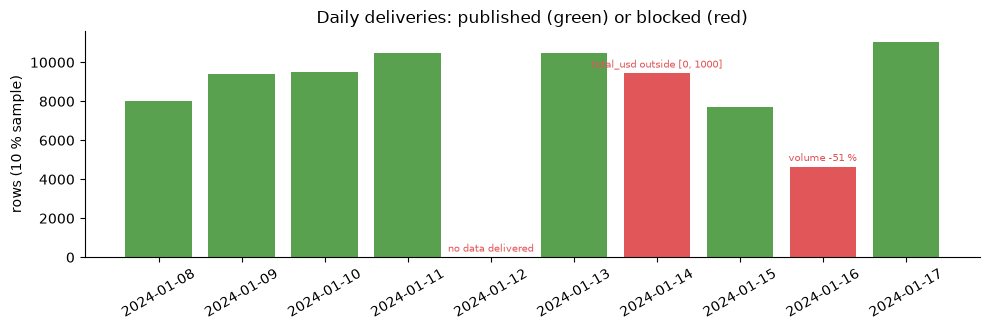

In [6]:
trips.refresh()
main = trips.scan().to_pandas()
on_main = main.groupby(main.pickup_at.dt.date).size()
expected = report[report.published].set_index("day").rows
print("main contains exactly the published days:", on_main.to_dict() == expected.to_dict())
print("table columns:", trips.schema().column_names)
print("payment_type NULL on 2024-01-08 (before v2):", bool(main[main.pickup_at.dt.date == dt.date(2024, 1, 8)].payment_type.isna().all()))

runs = requests.get(f"{MARQUEZ}/api/v1/namespaces/{RUN_NS}/jobs/load_trips_daily/runs", params={"limit": 50}, timeout=30).json()["runs"]
marquez = pd.DataFrame([{"run": r["startedAt"][:10], "state": r["state"]} for r in runs]).sort_values("run")
print(marquez.state.value_counts().to_string())
print("failed runs (run date; each run loads the previous day):", marquez[marquez.state == "FAILED"].run.tolist())

fig, ax = plt.subplots(figsize=(10, 3.4))
colors = ["#59A14F" if p else "#E15759" for p in report.published]
ax.bar(report.day.astype(str), report.rows, color=colors)
for x, (rows, why) in enumerate(zip(report.rows, report.reasons)):
    if why:
        ax.annotate(why.split(":")[0].split(" vs.")[0], (x, rows), xytext=(0, 4), textcoords="offset points",
                    ha="center", fontsize=7, color="#E15759")
ax.set(title="Daily deliveries: published (green) or blocked (red)", ylabel="rows (10 % sample)")
plt.xticks(rotation=30); plt.tight_layout(); plt.show()

### 6. Explanation for the dashboard owners

1. The incompatible type change on 2024-01-12 was stopped by the Schema Registry at the producer: no message was
   sent, and our loader reported the missing day instead of publishing a gap silently.
2. The sign bug on 2024-01-14 had a valid schema; only the contract's value rules found it on the audit branch. The
   rules tolerate a small share of odd values (a few 300-mile GPS errors per day), otherwise healthy days would fail.
3. The truncated export on 2024-01-16 had valid schema and values; only the volume check against recent days found it.
4. The compatible change on 2024-01-10 (`payment_type`) passed every control and evolved the table, so the controls
   do not block normal schema growth.
5. Each control sees a different kind of failure (structure, values, completeness), and write-audit-publish makes them
   enforceable: blocked days stay on the branch, and Marquez shows the reason in the run history.

## Submission Checklist

- [ ] Every day 2024-01-08 to 2024-01-17 has a decision: published, or blocked with a reason.
- [ ] Bad data never reaches `main` (prove it with row counts per day on `main`).
- [ ] The table schema evolves when the producer adds `payment_type`; older rows read it as NULL.
- [ ] Every run has lineage events in Marquez; failed runs carry the reason.
- [ ] The explanation names one control per incident.

A solution is in `02-Governed-Taxi-Feed-solution.ipynb`. Try the mission first.